<a href="https://colab.research.google.com/github/Symon-CNA/CNA/blob/main/Bissec%C3%A7%C3%A3oCNA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math as mt
import numpy as np
import matplotlib.pyplot as plt
import sys

h_min = 0
h_max = 1.5
tol = 0.00001
max_iter = 100

def f(H):
  f = (0.471405*(20*H)**(5/3))/(20+2*H)**(2/3) - 5
  return f

fa = f(h_min)
fb = f(h_max)

if fa * fb > 0:
    print(f"ERRO: O intervalo [{h_min}, {h_max}] não é válido!")
    print(f"f({h_min}) = {fa:.4f} e f({h_max}) = {fb:.4f} possuem o MESMO sinal.")
    print("O método não garante a existência de uma raiz nesse intervalo.")
    sys.exit()

#Listas de dados
historico_iter = []
historico_erro = []
historico_H = []

print(f"{'Niter':<10} | {'H (m)':<15} | {'Ea (%)':<15}")
print("-" * 45)

h_old = 0
for niter in range(1, max_iter + 1):
    H_med = (h_min + h_max) / 2.0

    # Cálculo do Erro Absoluto Relativo Percentual
    if niter == 1:
        Ea = 100.0  # Na primeira iteração o erro relativo é tomado como 100%
    else:
        Ea = abs((H_med - H_old) / H_med) * 100.0

    # Armazenando histórico
    historico_iter.append(niter)
    historico_H.append(H_med)
    historico_erro.append(Ea)

    # Exibição na tela
    print(f"{niter:<10} | {H_med:<15.6f} | {Ea:<15.6f}")

    # Critério de parada por tolerância
    if Ea < tol or abs(f(H_med)) < 1e-8:
        break

    # Atualização do intervalo [min, max]
    if f(h_min) * f(H_med) < 0:
        h_max = H_med
    else:
        h_min = H_med

    H_old = H_med

print("-" * 45)
print(f"Resultado final: H = {H_med:.4f} m (Esperado: H = 0.7023 m)")



Niter      | H (m)           | Ea (%)         
---------------------------------------------
1          | 0.750000        | 100.000000     
2          | 0.375000        | 100.000000     
3          | 0.562500        | 33.333333      
4          | 0.656250        | 14.285714      
5          | 0.703125        | 6.666667       
6          | 0.679688        | 3.448276       
7          | 0.691406        | 1.694915       
8          | 0.697266        | 0.840336       
9          | 0.700195        | 0.418410       
10         | 0.701660        | 0.208768       
11         | 0.702393        | 0.104275       
12         | 0.702026        | 0.052165       
13         | 0.702209        | 0.026076       
14         | 0.702301        | 0.013036       
15         | 0.702255        | 0.006518       
16         | 0.702278        | 0.003259       
17         | 0.702290        | 0.001630       
18         | 0.702295        | 0.000815       
19         | 0.702292        | 0.000407       
20         | 0


Tabela de dados salva em 'resultado_bisseccao.txt'


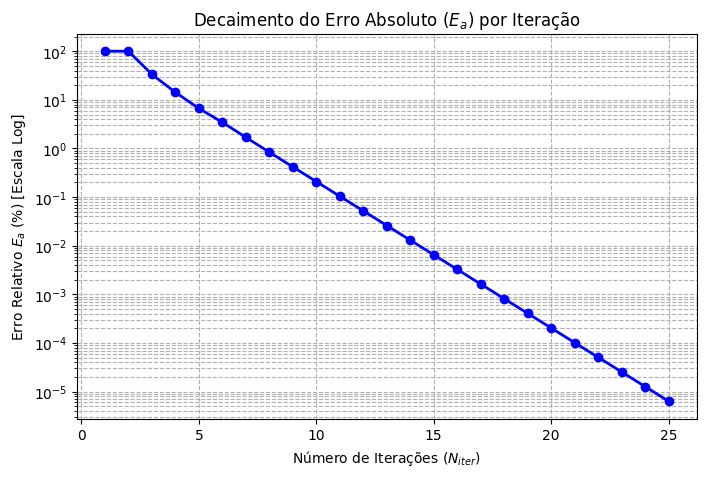

In [ ]:
# 4. Salvar os resultados em um arquivo de saída de texto (.txt)
with open("resultado_bisseccao.txt", "w") as arquivo:
    arquivo.write("Niter\t\tH(m)\t\tEa(%)\n")
    arquivo.write("="*40 + "\n")
    for i, h_val, err in zip(historico_iter, historico_H, historico_erro):
        arquivo.write(f"{i}\t\t{h_val:.6f}\t\t{err:.6f}\n")

print("\nTabela de dados salva em 'resultado_bisseccao.txt'")

# 5. Plot do gráfico: Ea x Niter
plt.figure(figsize=(8, 5))
plt.plot(historico_iter, historico_erro, 'o-', color='blue', linewidth=2, markersize=6)
plt.yscale('log')  # Escala logarítmica para visualização clara do decaimento do erro
plt.title('Decaimento do Erro Absoluto ($E_a$) por Iteração')
plt.xlabel('Número de Iterações ($N_{iter}$)')
plt.ylabel('Erro Relativo $E_a$ (%) [Escala Log]')
plt.grid(True, which="both", ls="--")
plt.show()